In [17]:
from astropy.io import fits
from astropy.wcs import WCS 
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle
from astropy.coordinates import SkyCoord
import astropy.units as u
from regions import Regions
from matplotlib.colors import PowerNorm
#from reproject import reproject_interp

image = 2

if image == 1:
    region = '126223'
    path = '../output/alma_sources/126223/'
    alma_image = path + '126223_cont_7MTM2TM1_jointdeconv.image.fits'
    spitzer = []
    for band in ['I1','I2','I3','I4']:
        spitzer.append(path+'0001_280.72520000_-4.04180000_GLM_02850+0000_mosaic_'+band+'.fits')
else:
    region = 'G304.8872+00.6356'
    path = '../output/alma_sources/G304.8872+00.6356/'
    alma_image = path + 'G304.8872+00.6356_cont_7MTM2TM1_jointdeconv.image.fits' 
    spitzer = []
    for band in ['I1','I2','I3','I4']:
        spitzer.append(path+'0001_197.05050000_-62.17280000_GLM_30450+0075_mosaic_'+band+'.fits')

print(spitzer)

['../output/alma_sources/G304.8872+00.6356/0001_197.05050000_-62.17280000_GLM_30450+0075_mosaic_I1.fits', '../output/alma_sources/G304.8872+00.6356/0001_197.05050000_-62.17280000_GLM_30450+0075_mosaic_I2.fits', '../output/alma_sources/G304.8872+00.6356/0001_197.05050000_-62.17280000_GLM_30450+0075_mosaic_I3.fits', '../output/alma_sources/G304.8872+00.6356/0001_197.05050000_-62.17280000_GLM_30450+0075_mosaic_I4.fits']


In [18]:
def regions_patch(regions,axs,i,j,wcs,alpha):
    for reg in regions:
        patch = reg.to_pixel(wcs).as_artist()
        patch.set_alpha(alpha)
        axs[i][j].add_artist(patch)

Set OBSGEO-B to   -23.022886 from OBSGEO-[XYZ].
Set OBSGEO-H to     5053.796 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


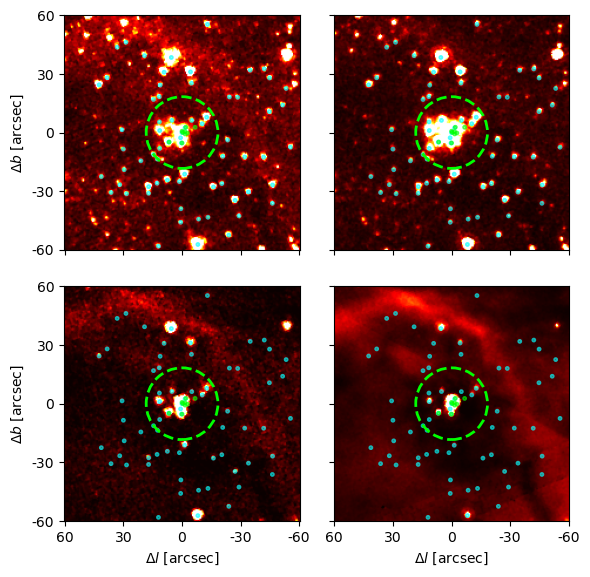

In [19]:
regs_spitzer = Regions.read(path+region+'_glimpse_s07_spitzer_sources.reg')
regs_alma = Regions.read(path+region+'_alma_sources.reg')

with fits.open(alma_image) as alma_fits:
    
    alma_wcs = WCS(alma_fits[0].header)
    ra_alma = alma_fits[0].header['CRVAL1']
    dec_alma = alma_fits[0].header['CRVAL2']

    alma_coord = SkyCoord(ra=ra_alma*u.deg, dec=dec_alma*u.deg,frame='icrs')

    l_alma = alma_coord.galactic.l.deg
    b_alma = alma_coord.galactic.b.deg

    
    counter = 0
    
    '''with fits.open(spitzer[0]) as spitzer_fits:
        spitzer_wcs = WCS(spitzer_fits[0].header)
        fig, axs = plt.subplots(2,2,figsize=(6,6),sharey=True,sharex=True,subplot_kw={'projection': spitzer_wcs})'''
    
    fig, axs = plt.subplots(2,2,figsize=(6,6),sharey=True,sharex=True,tight_layout=True)

    cmaps = ['Greys', 'Blues', 'Reds', 'Greens']

    for idx, band in enumerate(spitzer):
        with fits.open(band) as spitzer_fits:
            spitzer_wcs = WCS(spitzer_fits[0].header)

            x_alma, y_alma = spitzer_wcs.world_to_pixel_values(l_alma,b_alma)

            # ALMA field size (deg)
            alma_fov_deg = 0.0102
            alma_radius_arcsec = (alma_fov_deg / 2) * 3600  # arcsec

            # Spitzer pixel scale
            spitzer_pixscale = 0.6 * u.arcsec / u.pixel

            # Convert to pixels
            alma_radius_pix = (alma_radius_arcsec * u.arcsec / spitzer_pixscale).to_value(u.pixel)
            
            # Plot


            positive = spitzer_fits[0].data[spitzer_fits[0].data > 0]

            circle = Circle(
                (x_alma, y_alma),
                alma_radius_pix,
                edgecolor='lime',
                facecolor='none',
                linewidth=2,
                linestyle='--',
                label='ALMA region',
                zorder=10
            )

            alpha_val = 0.7
            

            if counter <2:

                axs[0][idx].imshow(spitzer_fits[0].data,origin='lower',cmap='hot',
                        norm= PowerNorm(gamma=2,vmin = 0,vmax=6))
                axs[0][idx].add_patch(circle)

                regions_patch(regs_spitzer,axs,0,idx,spitzer_wcs,alpha=alpha_val)
                regions_patch(regs_alma,axs,0,idx,spitzer_wcs,alpha=alpha_val)                

                counter = counter + 1
            else:
                if counter == 2:
                    axs[1][idx-2].imshow(spitzer_fits[0].data,origin='lower',cmap='hot',
                            norm=PowerNorm(gamma=2,vmin = 10,vmax=30))
                    axs[1][idx-2].add_patch(circle)

                    regions_patch(regs_spitzer,axs,1,idx-2,spitzer_wcs,alpha=alpha_val)
                    regions_patch(regs_alma,axs,1,idx-2,spitzer_wcs,alpha=alpha_val)
                    counter = counter +1
                else:
                    axs[1][idx-2].imshow(spitzer_fits[0].data,origin='lower',cmap='hot',
                            norm=PowerNorm(gamma=2,vmin = 30,vmax=80)) # 65 was before
                    axs[1][idx-2].add_patch(circle)

                    regions_patch(regs_spitzer,axs,1,idx-2,spitzer_wcs,alpha=alpha_val)
                    regions_patch(regs_alma,axs,1,idx-2,spitzer_wcs,alpha=alpha_val)
    
    
    
    '''for ax in axs.ravel():

        l_spitzer = ax.coords[0]
        l_spitzer.set_format_unit('arcsec')
        b_spitzer = ax.coords[1]

        l_spitzer.set_major_formatter('s')   # arcsec
        b_spitzer.set_major_formatter('s')

        l_spitzer.set_axislabel("l (arcsec)")
        b_spitzer.set_axislabel("b (arcsec)")

        l_spitzer.set_ticks(spacing=50*u.arcsec)
        b_spitzer.set_ticks(spacing=50*u.arcsec)

    axs[0][0].set_xticklabel(False)
    axs[0][0].set_xaxislabel("")
    axs[0][1].set_xticklabel_visible(False)
    axs[0][1].set_xaxislabel("")
    axs[0][1].set_yticklabel_visible(False)
    axs[0][1].set_yaxislabel("")
    axs[1][1].set_yticklabel_visible(False)
    axs[1][1].set_yaxislabel("")'''

    axs[0][0].set_yticks(np.linspace(0,200,5))
    axs[0][0].set_yticklabels(np.linspace(-60,60,5,dtype=int))

    axs[1][1].set_xticks(np.linspace(0,200,5))
    axs[1][1].set_xticklabels(np.linspace(60,-60,5,dtype=int))
    
    axs[0][0].set_ylabel(r'$\Delta b$ [arcsec]')
    axs[1][0].set_ylabel(r'$\Delta b$ [arcsec]')
    axs[1][0].set_xlabel(r'$\Delta l$ [arcsec]')
    axs[1][1].set_xlabel(r'$\Delta l$ [arcsec]')

plt.savefig('../output/figures/IRAC_IMAGE_'+region+'glimpse_s07.pdf',format='pdf',dpi=300)
plt.show()


Set OBSGEO-B to   -23.022886 from OBSGEO-[XYZ].
Set OBSGEO-H to     5053.796 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


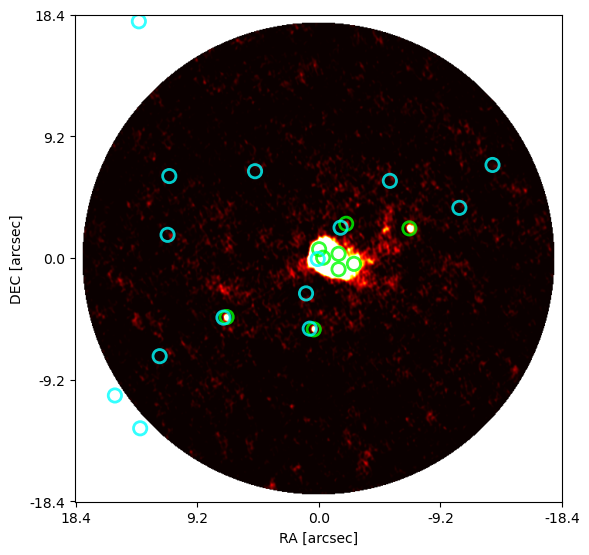

In [20]:
with fits.open(alma_image) as alma_fits:

    alma_wcs = WCS(alma_fits[0].header)
    ra_alma = alma_fits[0].header['CRVAL1']
    dec_alma = alma_fits[0].header['CRVAL2']

    alma_coord = SkyCoord(ra=ra_alma*u.deg, dec=dec_alma*u.deg,frame='icrs')

    l_alma = alma_coord.galactic.l.deg
    b_alma = alma_coord.galactic.b.deg

    fig, ax = plt.subplots(figsize=(6,6),tight_layout=True)

    with fits.open(spitzer[0]) as spitzer_fits:
        spitzer_wcs = WCS(spitzer_fits[0].header)

        x_alma, y_alma = spitzer_wcs.world_to_pixel_values(l_alma,b_alma)


        
        regs_alma = Regions.read(path+region+'_alma_sources.reg')
        
        ax.imshow(alma_fits[0].data,origin='lower',cmap='hot', norm= PowerNorm(gamma=2,vmin = 0,vmax=0.001))
                        #norm=LogNorm(
                        #    vmin=positive.min(),
                        #    vmax=positive.min()*10))        
        
        
        regs_alma = Regions.read(path+region+'_alma_sources.reg')
        

        for reg in regs_alma:
            patch = reg.to_pixel(alma_wcs).as_artist()

            # inner circle (main)
            inner = reg.to_pixel(alma_wcs).as_artist()
            inner.set_alpha(0.8)

            # outer circle (slightly larger "halo")
            outer = reg.to_pixel(alma_wcs).as_artist()

            # scale radius slightly larger
            outer.radius *= 1.2

            outer.set_edgecolor("black")
            outer.set_linewidth(4)
            outer.set_alpha(0.5)

            #ax.add_patch(outer)
            ax.add_patch(inner)
        
        for reg in regs_spitzer:
            patch = reg.to_pixel(alma_wcs).as_artist()

            # inner circle (main)
            inner = reg.to_pixel(alma_wcs).as_artist()
            inner.set_alpha(0.8)

            # outer circle (slightly larger "halo")
            outer = reg.to_pixel(alma_wcs).as_artist()

            # scale radius slightly larger
            outer.radius *= 1.2

            outer.set_edgecolor("black")
            outer.set_linewidth(4)
            outer.set_alpha(0.5)

            #ax.add_patch(outer)
            ax.add_patch(inner)

    max_val = alma_fits[0].data.shape[0]

ax.set_yticks(np.linspace(0,max_val,5))
ax.set_yticklabels(np.linspace(-18.4,18.4,5))
ax.set_xticks(np.linspace(0,max_val,5))
ax.set_xticklabels(np.linspace(18.4,-18.4,5))

ax.set_xlabel('RA [arcsec]')

ax.set_ylabel('DEC [arcsec]')


plt.savefig('../output/figures/ALMA_IMAGE_'+region+'_glimpse_s07.pdf',format='pdf',dpi=300)

In [8]:
import matplotlib
matplotlib.scale.get_scale_names()

['asinh', 'function', 'functionlog', 'linear', 'log', 'logit', 'symlog']